# Analisi modale e statistica della sala secondo la teoria di Schroeder
Il parsing dei dati `.mdat` esportati da REW avviene tramite il modulo `rew_io`.

## Costanti della stanza:

In [1]:
LX, LY, LZ = 5.70, 4.80, 2.48           # m
V  = LX * LY * LZ                        # 67.85 m^3
S  = 2 * (LX*LY + LX*LZ + LY*LZ)         # 106.8 m^2
LT = 4 * (LX + LY + LZ)                  # somma spigoli, 51.9 m
c  = 343.0                               # m/s (~20 degC)

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

from rew_io import ROOM_DIR

print(f'Dimensioni: {LX:.2f} x {LY:.2f} x {LZ:.2f} m')
print(f'Volume = {V:.2f} m^3')
print(f'Superficie = {S:.1f} m^2')
print(f'Dati salvati in: {ROOM_DIR}')

Dimensioni: 5.70 x 4.80 x 2.48 m
Volume = 67.85 m^3
Superficie = 106.8 m^2
Dati salvati in: /Users/matteob/Code/acoustics/data/room


## Parser
Un file `.mdat` non è un semplice array di misura per una IR, ma contiene dati aggiuntivi impacchettati da REW in un formato Java. Il **parser** `rew_io` si occupa di estrapolare i dati di interesse da tali pacchetti, su tutti le Impulse Response.
Il metodo `read_mdat` riceve il percorso in cui sono salvati i dati, e restituisce un oggetto Measurment composto di:
- `path`: Banalmente il percorso di salvataggio dati, già in input;
- `field`: tramite `parse_measdata_fields` restituisce un dizionario coi metadati della misura;
- `irs`: tramite `extract_irs` restituisce gli effettivi array di misura degli sweep effettuati su REW, con un controllo sulla lunghezza degli array stessi;
- `ir_len`: lunghezza utilizzato per il filtro sopra citata, impostata ad un default.

*NOTA: si può tranquillamente togliere la proprietà `room_dims` di `Measurement`, in quanto i dati dimensionali della stanza intrinseci nelle misure *.mdat* sono errati.*

In [2]:
from rew_io import read_mdat

m = read_mdat(ROOM_DIR / 'Danger_Pos1.mdat')
print(f"- Numero di sweep nel file:", len(m.irs))
print(f"- Sweep eseguito tra {m.fields['startFreq']:.1f} Hz e {m.fields['endFreq']:.1f} Hz, con risoluzione di {m.fields['freqStep']:.3f} Hz.")
print(f"- Dati acquisiti con {len(m.irs[0]):.0f} campioni, a {m.fields['sampleRate']:.0f} Hz.")

- Numero di sweep nel file: 3
- Sweep eseguito tra 20.1 Hz e 22000.1 Hz, con risoluzione di 0.366 Hz.
- Dati acquisiti con 131072 campioni, a 48000 Hz.


## Estrazione dati per le 5 posizioni
Analisi preliminare dei dati acquisiti:
- Calcolo della correlazione tra i 3 sweep come controllo sulla riproducibilità.
- SNR per posizione per attendibilità della IR

In [3]:
import numpy as np
from rew_io import read_mdat

POSITIONS = [1, 2, 3, 4, 5]

corrs = []
for pos in POSITIONS:
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    irs, mean_ir = m.irs, m.mean_ir

    # Correlazione tra gli sweep acquisiti in ciascuna posizione
    temp = []
    for i in range(len(irs)):
        for j in range(i + 1, len(irs)):
            temp.append(np.corrcoef(irs[i], irs[j])[0, 1])

    # Registro il minimo in quanto peggior caso di correlazione
    corrs.append(np.min(temp))

    print(f"Posizione {pos}: {np.min(temp):.6f}")


Posizione 1: 0.998758
Posizione 2: 0.990943
Posizione 3: 0.992562
Posizione 4: 0.990373
Posizione 5: 0.988197


## Media delle IRs
Essendo gli sweep per ogni posizione consistenti, spostiamo l'analisi sulle IR mediate, ottenendo verosimilmente un risultato più vicino al valore vero.

*NOTA: eventualmente includere il discorso dell'allineamento*

In [4]:
import numpy as np
from rew_io import read_mdat

POSITIONS = [1, 2, 3, 4, 5]

for pos in POSITIONS:
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    mean_ir, fs = m.mean_ir, m.fs

    # SNR
    noise = mean_ir[:40000] # campioni prima dell'inizio dello sweep
    signal = np.abs(mean_ir).max() # riduco il segnale al suo massimo, per escludere segnale di fondo
    snr = 20*np.log10(signal / np.std(noise))
    print(f"Posizione {pos}: SNR = {snr:.2f} dB")

Posizione 1: SNR = 82.14 dB
Posizione 2: SNR = 78.66 dB
Posizione 3: SNR = 79.17 dB
Posizione 4: SNR = 80.12 dB
Posizione 5: SNR = 68.16 dB


## Verifica allineamento IRs
È necessario verificare che le misure, o meglio le risposte impulsive estratte dagli sweep su REW, siano allineate, in modo da avere più avanti un'unica finestra di integrazione per l'integrale di Schroeder.

In [5]:
data = []
for pos in POSITIONS:
    data.append(read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat'))

pass

## Integrale di Schröder
Il modulo `integration` incapsula i passaggi in una dataclass `BandDecay`:

1. `BandDecay.from_ir(ir, fc, fs)` — filtra la IR nella banda d'ottava (fase nulla, `sosfiltfilt`) e taglia al picco, cioè al suono diretto: è l'estremo **iniziale** di integrazione.
2. `.find_limits()` — costruzione di **Lundeby** per l'estremo **finale**: il punto in cui il decadimento incontra il rumore di fondo. Va trovato iterativamente perché pendenza del decadimento e livello di rumore si stimano a vicenda.
3. `.schroeder()` — integrale all'indietro sull'energia troncata e depurata del rumore, normalizzato a 0 dB.

Senza il troncamento la coda di rumore, essendo stazionaria, contribuisce sempre di più andando indietro nel tempo: la curva si appiattisce su un plateau e il tempo di riverberazione risulta sovrastimato.


Posizione 1: t_cross = 1.209 s, pendenza = -23.2 dB/s, 4 iterazioni, convergenza = True
Posizione 2: t_cross = 1.360 s, pendenza = -19.5 dB/s, 7 iterazioni, convergenza = True
Posizione 3: t_cross = 1.307 s, pendenza = -21.9 dB/s, 5 iterazioni, convergenza = True
Posizione 4: t_cross = 0.745 s, pendenza = -41.1 dB/s, 3 iterazioni, convergenza = True
Posizione 5: t_cross = 0.979 s, pendenza = -28.8 dB/s, 3 iterazioni, convergenza = True


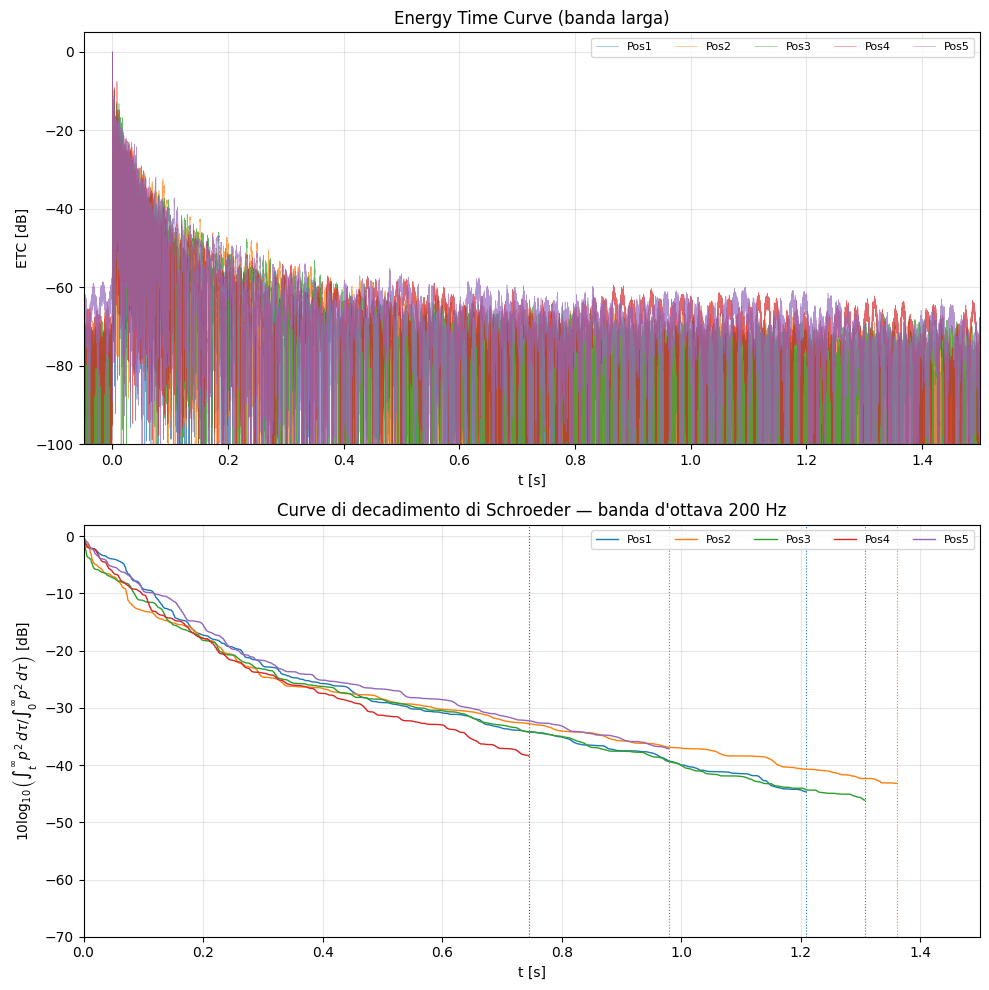

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from integration import BandDecay

POSITIONS = [1, 2, 3, 4, 5]
FC = 200.0 # centro della banda d'ottava analizzata [Hz]

mean_irs, bands, sch_curves = [], [], []
fig, ax = plt.subplots(figsize=(10, 10), ncols=1, nrows=2)

for pos in POSITIONS:
    data = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    ir, fs = data.mean_ir, data.fs # IR della posizione corrente
    mean_irs.append(ir)

    # Energy Time Curve, a banda larga
    ipk = int(np.abs(ir).argmax())
    t   = (np.arange(len(ir)) - ipk) / fs # tempo centrato sul picco
    etc = 20*np.log10(np.abs(ir)/np.abs(ir).max() + 1e-12)
    ax[0].plot(t, etc, lw=0.4, alpha=0.7, label=f'Pos{pos}')

    # Banda d'ottava -> estremi di integrazione -> integrale di Schroeder
    band = BandDecay.from_ir(ir, FC, fs).find_limits()
    sch  = band.schroeder()
    bands.append(band)
    sch_curves.append(sch)

    linea, = ax[1].plot(band.schroeder_time(sch), sch, lw=1.0, label=f'Pos{pos}')
    ax[1].axvline(band.t_cross, color=linea.get_color(), ls=':', lw=0.8)

    print(f"Posizione {pos}: t_cross = {band.t_cross:.3f} s, "
          f"pendenza = {band.slope:.1f} dB/s, "
          f"{band.n_iter} iterazioni, convergenza = {band.ok}")

ax[0].set_xlabel('t [s]')
ax[0].set_ylabel('ETC [dB]')
ax[0].set_xlim(-0.05, 1.5)
ax[0].set_ylim(-100, 5)
ax[0].set_title('Energy Time Curve (banda larga)')
ax[0].grid(alpha=0.3)
ax[0].legend(loc='upper right', ncol=5, fontsize=8)

ax[1].set_xlabel('t [s]')
ax[1].set_ylabel(r'$10\log_{10}\left(\int_t^\infty p^2\,d\tau / \int_0^\infty p^2\,d\tau\right)$ [dB]')
ax[1].set_xlim(0, 1.5)
ax[1].set_ylim(-70, 2)
ax[1].set_title(f'Curve di decadimento di Schroeder — banda d\'ottava {FC:.0f} Hz')
ax[1].grid(alpha=0.3)
ax[1].legend(loc='upper right', ncol=5, fontsize=8)

fig.tight_layout()
plt.show()
